# Credit Risk Intelligence System
## 01. Data Quality & Exploratory Data Analysis

### Objective

The objective of this notebook is to perform an initial assessment of the
Default of Credit Card Clients dataset.

Before developing a Probability of Default (PD) model, we need to understand
the structure, quality, consistency and distribution of the available data.

### Scope

This notebook covers:

- Dataset structure and data types.
- Missing values.
- Duplicate records and identifiers.
- Descriptive statistics.
- Categorical variables and potential inconsistencies.
- Target variable distribution.

**Important:** No records are removed or modified during this initial assessment.

In [1]:
#Importar librerias
from pathlib import Path
import pandas as pd

In [2]:
# Directorio raíz del proyecto
PROJECT_ROOT = Path.cwd().parent

# Ruta del archivo
DATA_PATH = PROJECT_ROOT / "Data" / "default of credit card clients.xls"

# Cargar dataset
df = pd.read_excel(DATA_PATH, header=1)

print("Dataset :", df.shape)

Dataset cargado: (30000, 25)


In [4]:
display(df.head())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
for column in df.columns:
    print(f"- {column}")

Dataset dimensions: (30000, 25)

Column names:
- ID
- LIMIT_BAL
- SEX
- EDUCATION
- MARRIAGE
- AGE
- PAY_0
- PAY_2
- PAY_3
- PAY_4
- PAY_5
- PAY_6
- BILL_AMT1
- BILL_AMT2
- BILL_AMT3
- BILL_AMT4
- BILL_AMT5
- BILL_AMT6
- PAY_AMT1
- PAY_AMT2
- PAY_AMT3
- PAY_AMT4
- PAY_AMT5
- PAY_AMT6
- default payment next month


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [7]:
# Resumen de tipos de datos
dtype_summary = (
    df.dtypes
    .value_counts()
    .rename_axis("Data type")
    .reset_index(name="Number of columns")
)

display(dtype_summary)

,Data type,Number of columns
0,int64,25


In [8]:
# Cantidad de valores nulos por columna
missing_summary = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Missing percentage (%)": df.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing percentage (%)",
    ascending=False
)

display(missing_summary)

,Missing values,Missing percentage (%)
ID,0,0.0
BILL_AMT2,0,0.0
PAY_AMT6,0,0.0
PAY_AMT5,0,0.0
PAY_AMT4,0,0.0
PAY_AMT3,0,0.0
PAY_AMT2,0,0.0
PAY_AMT1,0,0.0
BILL_AMT6,0,0.0
BILL_AMT5,0,0.0


In [9]:
# Registros completamente duplicados
duplicate_rows = df.duplicated().sum()

print(f"Completely duplicated records: {duplicate_rows:,}")

Completely duplicated records: 0


In [10]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [11]:
TARGET = "default payment next month"

if TARGET not in df.columns:
    raise KeyError(f"Target variable not found: {TARGET}")

target_distribution = (
    df[TARGET]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Customers")
)

target_distribution["Percentage (%)"] = (
    target_distribution["Customers"] / len(df) * 100
)

display(target_distribution)

,Customers,Percentage (%)
default payment next month,,
0,23364,77.88
1,6636,22.12


In [13]:
# Variables categóricas y sus valores permitidos según la codificación del dataset
expected_categories = {
    "SEX": [1, 2],
    "EDUCATION": [1, 2, 3, 4, 5, 6, 0],
    "MARRIAGE": [1, 2, 3, 0]
}

for column, valid_values in expected_categories.items():
    if column in df.columns:
        invalid_values = df.loc[
            ~df[column].isin(valid_values) & df[column].notna(),
            column
        ]

        print(f"{column}: {len(invalid_values):,} potentially invalid records")
        if not invalid_values.empty:
            print("Unexpected values:", sorted(invalid_values.unique()))

SEX: 0 potentially invalid records
EDUCATION: 0 potentially invalid records
MARRIAGE: 0 potentially invalid records


In [14]:
# No se detectan valores nulos, duplicados ni categorias fuera de rango
# en pay y bill se detectan valores negativos

In [15]:
pay_columns = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

for column in pay_columns:
    print(f"\n{column}")
    display(
        df[column]
        .value_counts()
        .sort_index()
        .rename("Customers")
        .to_frame()
    )


PAY_0


,Customers
PAY_0,
-2,2759
-1,5686
0,14737
1,3688
2,2667
3,322
4,76
5,26
6,11



PAY_2


,Customers
PAY_2,
-2,3782
-1,6050
0,15730
1,28
2,3927
3,326
4,99
5,25
6,12



PAY_3


,Customers
PAY_3,
-2,4085
-1,5938
0,15764
1,4
2,3819
3,240
4,76
5,21
6,23


... (2 outputs left out)


PAY_5


,Customers
PAY_5,
-2,4546
-1,5539
0,16947
2,2626
3,178
4,84
5,17
6,4
7,58



PAY_6


,Customers
PAY_6,
-2,4895
-1,5740
0,16286
2,2766
3,184
4,49
5,13
6,19
7,46


In [16]:
bill_columns = [
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"
]

negative_summary = pd.DataFrame({
    "Negative records": [(df[col] < 0).sum() for col in bill_columns],
    "Percentage (%)": [(df[col] < 0).mean() * 100 for col in bill_columns]
}, index=bill_columns)

display(negative_summary)

,Negative records,Percentage (%)
BILL_AMT1,590,1.966667
BILL_AMT2,669,2.230000
BILL_AMT3,655,2.183333
BILL_AMT4,675,2.250000
BILL_AMT5,655,2.183333
BILL_AMT6,688,2.293333


In [17]:
comparison = df.groupby("default payment next month").agg({
    "LIMIT_BAL": ["mean", "median"],
    "AGE": ["mean", "median"],
    "BILL_AMT1": ["mean", "median"],
    "PAY_AMT1": ["mean", "median"],
    "PAY_0": ["mean", "median"]
})

display(comparison.T)

default payment next month              0              1
LIMIT_BAL mean              178099.726074  130109.656420
          median            150000.000000   90000.000000
AGE       mean                  35.417266      35.725738
          median                34.000000      34.000000
BILL_AMT1 mean               51994.227273   48509.162297
          median             23119.500000   20185.000000
PAY_AMT1  mean                6307.337357    3397.044153
          median              2459.500000    1636.000000
PAY_0     mean                  -0.211222       0.668174
          median                 0.000000       1.000000

### Interpretation of Billing Amounts and Payment Status Variables

**Billing Amounts (`BILL_AMT1` to `BILL_AMT6`)**

Negative billing amounts may represent customer credit balances resulting from overpayments, refunds, or account adjustments. These observations should be preserved, as they may contain relevant information about customer financial behavior.

No negative values were removed or replaced during this exploration.

**Payment Status (`PAY_0`, `PAY_2` to `PAY_6`)**

These variables represent payment status codes rather than monetary amounts. Their values have different meanings:

- `-2`: No consumption during the month.
- `-1`: Payment made on time.
- `0`: Revolving credit without recorded payment delay.
- `1` to `8`: Payment delay in months.

These variables should not be interpreted as conventional continuous numerical measurements. Their encoding will require consideration during the modeling preparation stage.

**Exploration conclusion:** Both variable groups contain meaningful information and will be retained without modification at this stage.

## Data Quality Assessment

The initial data quality assessment identified the following:

- **Dataset size:** 30,000 observations and 24 columns.
- **Missing values:** No missing values detected.
- **Duplicate records:** No duplicated rows or customer IDs detected.
- **Target variable:** 22.12% default cases and 77.88% non-default cases.
- **Categorical variables:** Some variables contain special codes that require interpretation.
- **Billing amounts:** Negative values were identified and retained, as they may represent valid account balances.
- **Payment status:** Payment status variables contain categorical codes rather than conventional continuous measurements.

Overall, the dataset is suitable for further analysis. However, some variables will require specific treatment during the feature preparation and modeling stages.

No records were removed or modified during this assessment.

## Exploratory Data Analysis – Key Findings

The exploratory analysis revealed several relevant patterns:

1. **Target imbalance:** Approximately 22.12% of customers experienced payment default, indicating a moderate class imbalance.

2. **Credit limits:** Customers who defaulted showed lower average and median credit limits compared with non-defaulting customers.

3. **Payment behavior:** The `PAY_0` variable showed a less favorable payment status among customers who defaulted.

4. **Payment amounts:** Customers who defaulted had lower average payment amounts in `PAY_AMT1`.

5. **Age:** The age distribution was relatively similar between defaulting and non-defaulting customers.

These findings represent descriptive associations and do not imply causal relationships.

The results provide an initial understanding of the dataset and help identify variables that may be relevant for subsequent predictive modeling.

## Graficos


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Directory to save visualizations
FIGURES_PATH = PROJECT_ROOT / "reports" / "figures"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

# General visualization style
sns.set_theme(style="whitegrid", context="notebook")

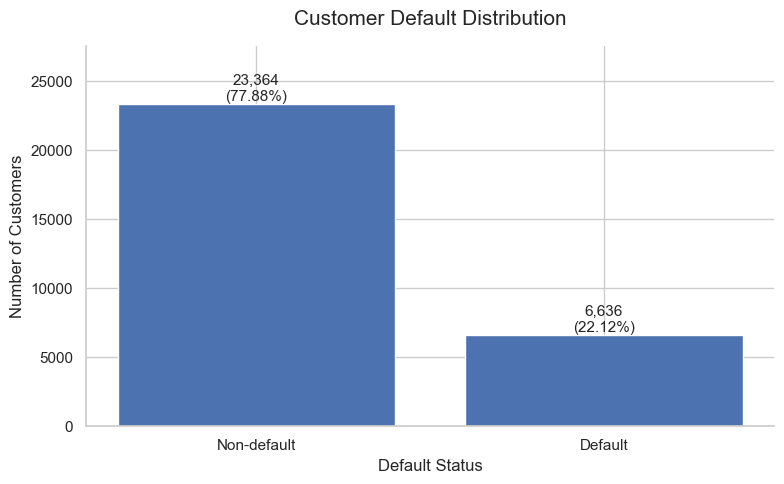

In [19]:
TARGET = "default payment next month"

target_counts = df[TARGET].value_counts().sort_index()

labels = ["Non-default", "Default"]
values = target_counts.values

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(labels, values)

# Add percentages and counts above bars
for bar, value in zip(bars, values):
    percentage = value / len(df) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title("Customer Default Distribution", fontsize=15, pad=15)
ax.set_xlabel("Default Status")
ax.set_ylabel("Number of Customers")

ax.set_ylim(0, max(values) * 1.18)

sns.despine()
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)


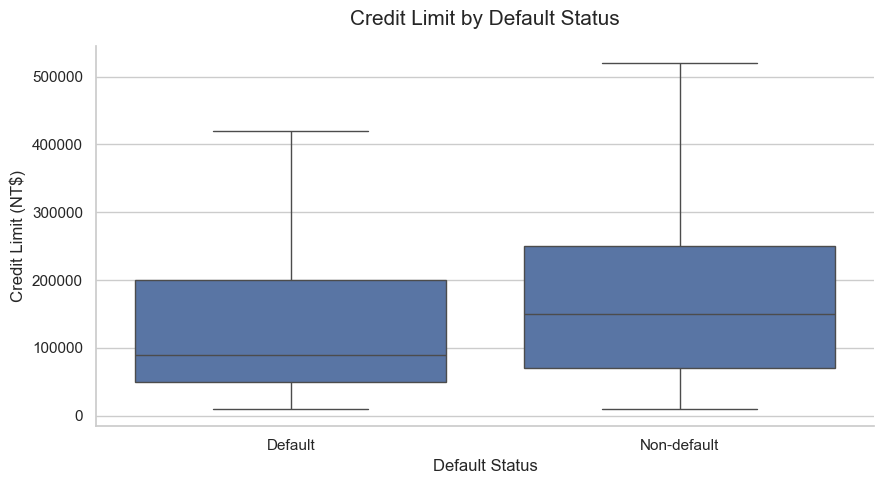

In [20]:
plot_df = df.copy()

plot_df["Default Status"] = plot_df[TARGET].map({
    0: "Non-default",
    1: "Default"
})

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=plot_df,
    x="Default Status",
    y="LIMIT_BAL",
    showfliers=False,
    ax=ax
)

ax.set_title("Credit Limit by Default Status", fontsize=15, pad=15)
ax.set_xlabel("Default Status")
ax.set_ylabel("Credit Limit (NT$)")

ax.ticklabel_format(style="plain", axis="y")

sns.despine()
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "credit_limit_by_default.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

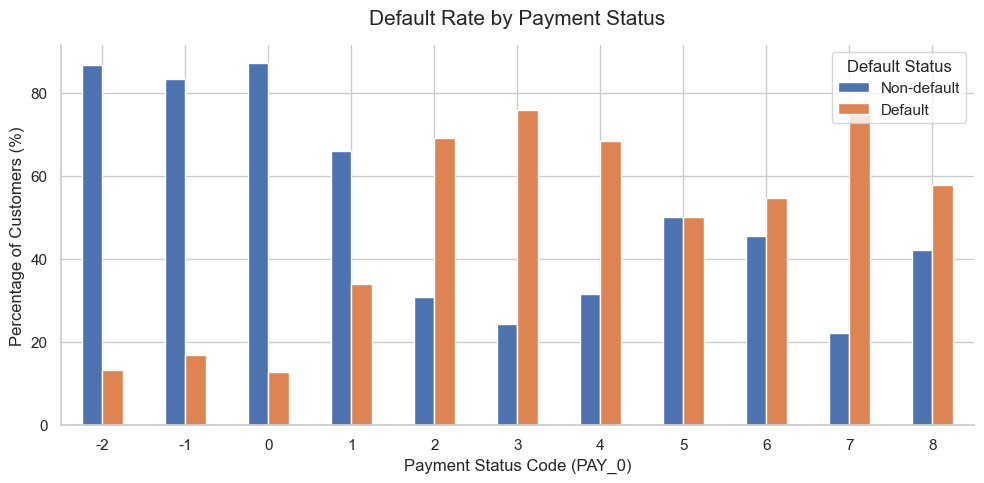

In [21]:
payment_distribution = pd.crosstab(
    df["PAY_0"],
    df[TARGET],
    normalize="index"
) * 100

payment_distribution = payment_distribution.rename(columns={
    0: "Non-default",
    1: "Default"
})

fig, ax = plt.subplots(figsize=(10, 5))

payment_distribution.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Default Rate by Payment Status", fontsize=15, pad=15)
ax.set_xlabel("Payment Status Code (PAY_0)")
ax.set_ylabel("Percentage of Customers (%)")

ax.legend(title="Default Status")
ax.tick_params(axis="x", rotation=0)

sns.despine()
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "payment_status_by_default.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

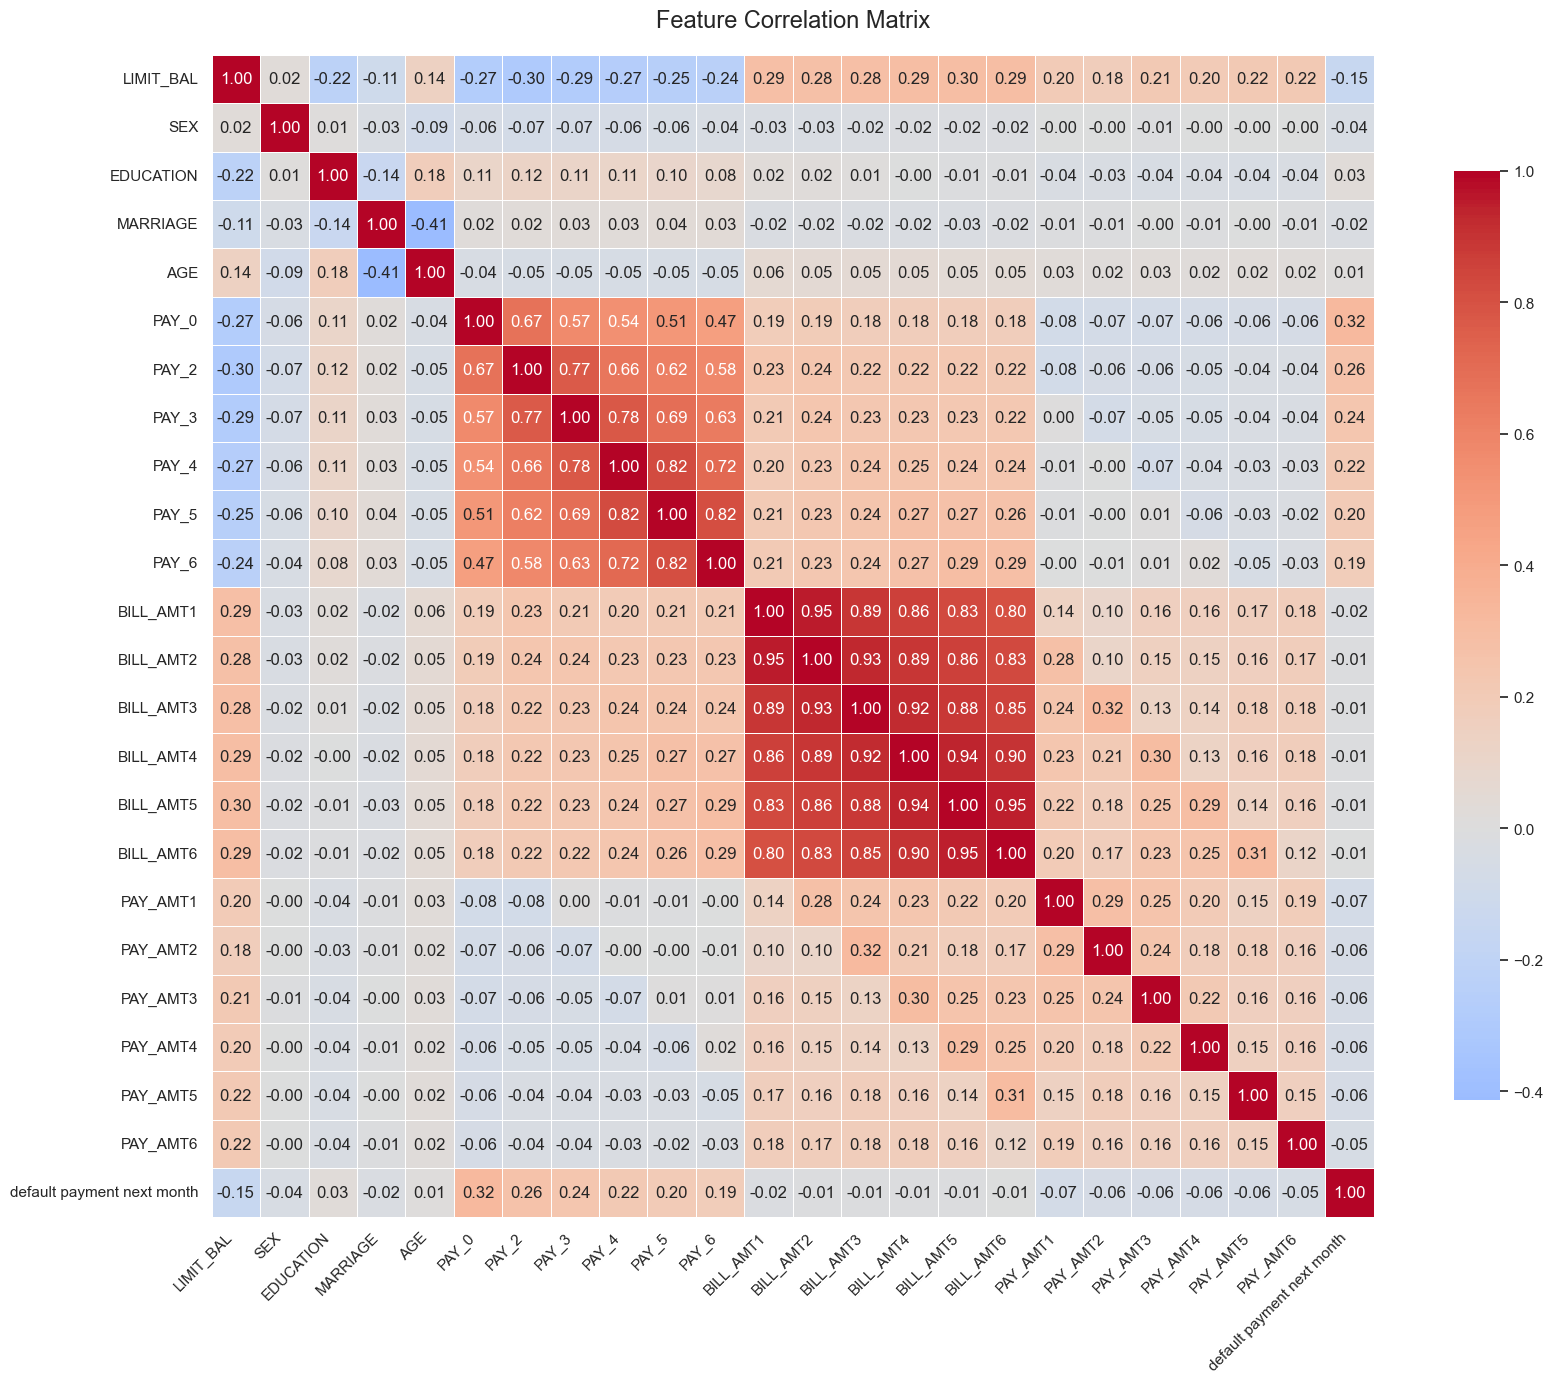

In [22]:
# Select numerical columns for correlation analysis
correlation_matrix = df.drop(columns=["ID"]).corr()

fig, ax = plt.subplots(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8},
    ax=ax
)

ax.set_title("Feature Correlation Matrix", fontsize=17, pad=20)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()